# TDA : Clustering des diagrammes de persistance des scans 3D Caesar
## Femmes

#### Paramètres préliminaires

- Packages nécessaires

In [1]:
import utils
import os

np = utils.importer('numpy')
plt = utils.importer('matplotlib.pyplot')
pickle = utils.importer('pickle')
meshio = utils.importer('meshio')

In [2]:
pathglob = 'E:/TDA/Female/'
all_scans = os.listdir(pathglob)
nb_scans = len(all_scans)

- Fonction qui renvoie le nuage de points du scan

In [3]:
def scan_from_index(i):
    path = pathglob + str(all_scans[i])
    scan = meshio.read(path)
    scan = scan.points
    return scan

### Affichage des scans

- On définit des fonctions qui affichent un scan 3D

In [4]:
def plot_scan_3D_interactive(i):
    scan = scan_from_index(i)
    points_set = utils.point_set(scan)
    points_set.plot(color='green', opacity=0.5, size=2)

### Diagrammes de persistance

- Paramètres de base

In [5]:
min_persistence = 3

* On importe les diagrammes et les diagrammes décolorés précédemment sauvegardés

In [6]:
with open ('./Data/XX.bin', 'rb') as fp:
    X = pickle.load(fp)

with open ('./Data/XX_decolor.bin', 'rb') as fp:
    X_decolor = pickle.load(fp)

### Distance entre les diagrammes (Wasserstein)

* On charge les distances, par homologie, précédemment calculées

In [7]:
with open ('./Data/XX_Dist_H0.bin', 'rb') as fp:
    dict_dist_0 = pickle.load(fp)
with open ('./Data/XX_Dist_H1.bin', 'rb') as fp:
    dict_dist_1 = pickle.load(fp)
with open ('./Data/XX_Dist_H2.bin', 'rb') as fp:
    dict_dist_2 = pickle.load(fp)

* On calcule les distances

In [8]:
dict_dist = {}
for key in dict_dist_1.keys():
    dict_dist[key] = (dict_dist_0[key]**2 + dict_dist_1[key]**2 + dict_dist_2[key]**2)**0.5

* On choisit le degré d'homologie

In [9]:
d_d = dict_dist

- On affiche les distances maximum et minimum

In [10]:
max_key = max(d_d, key=d_d.get)
min_key = min(d_d, key=d_d.get)

print("max", max_key, d_d[max_key])
print("min", min_key, d_d[min_key])

max (579, 908) 377.43045778901603
min (770, 1385) 6.108078565787477


- On affiche les scans 3D des plus distants

In [11]:
plot_scan_3D_interactive(max_key[0])
plot_scan_3D_interactive(max_key[1])

- On affiche les scans 3D des plus proches

In [12]:
plot_scan_3D_interactive(min_key[0])
plot_scan_3D_interactive(min_key[1])

### Clustering hiérarchique

- On fait un clustering hiérarchique

In [13]:
dendrogram, linkage, fcluster = utils.importer(
    'scipy.cluster.hierarchy', 'dendrogram', 'linkage', 'fcluster')

_, distances = zip(*sorted(d_d.items()))

In [14]:
Z = linkage(distances, metric='precomputed',
            method='ward', optimal_ordering=True)

- Voici le dendrogramme du clustering

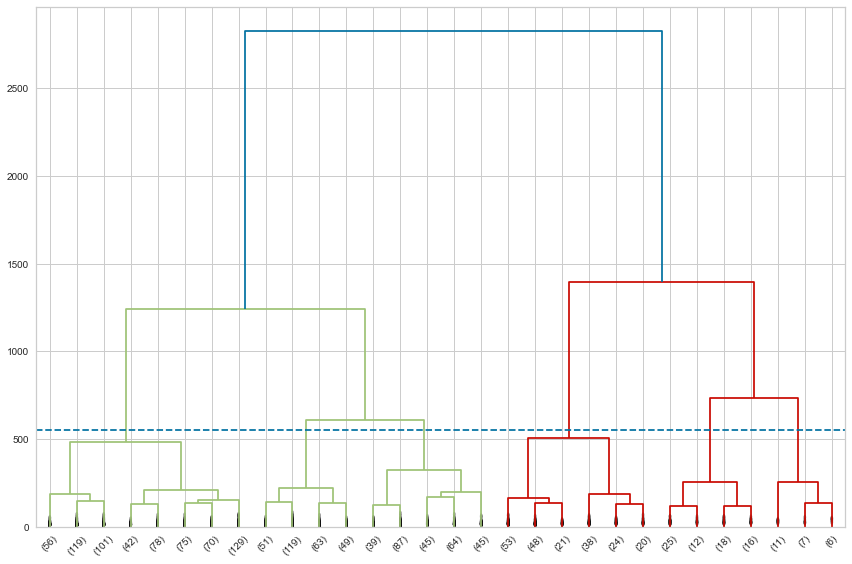

In [35]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(1, 1, 1)

dendrogram(Z, ax=ax, truncate_mode='lastp', show_contracted=True)
plt.plot([0, 300], [550, 550], 'b--')
plt.tight_layout()
plt.savefig('E:/Projet-M2/2021-m2-ditex-morphotypes/Images/FDENDWARD.jpg', dpi=200);

### Courbe elbow du clustering

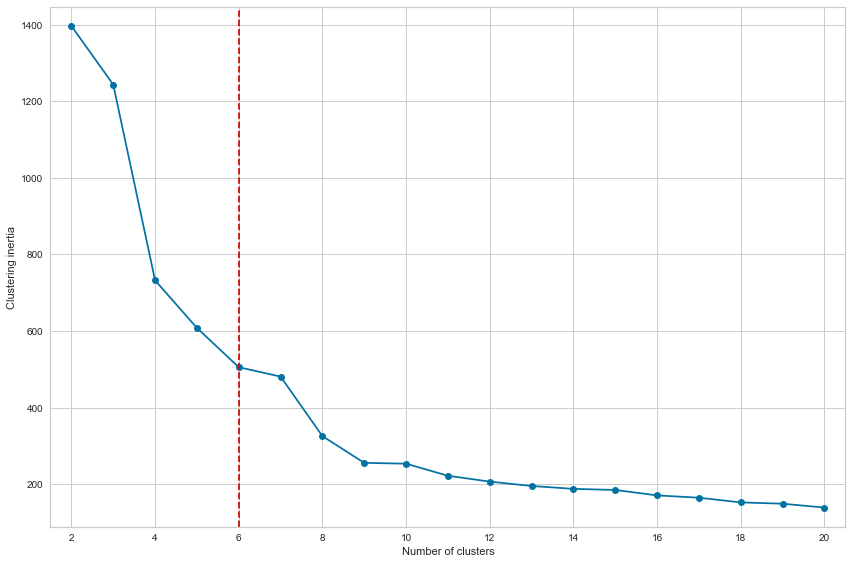

In [33]:
temp = 20

fig = plt.figure(figsize=(12, 8))
ymin, ymax = np.min(Z[::-1, 2][1:temp]), np.max(Z[::-1, 2][1:temp])
a = (ymax - ymin) / 25

plt.plot(range(2, temp+1), Z[::-1, 2][1:temp], 'o-')
plt.plot([6, 6], [ymin-a, ymax+a], 'r--')
plt.ylim(ymin-a, ymax+a)
plt.xticks(range(2, 21, 2))
plt.xlim(1.5, 20.5)
plt.xlabel('Number of clusters')
plt.ylabel('Clustering inertia')
plt.tight_layout()
plt.grid(True)
plt.savefig('E:/Projet-M2/2021-m2-ditex-morphotypes/Images/FWElbow.jpg', dpi=200);

### Indice de Davies-Bouldin

- Voici la courbe associée à cet indice quand on fait varier le nombre de clusters

In [17]:
# SDB_list = []
# borne_nb_clus = 21

# for i in range(2, borne_nb_clus):
#     nb_clus = i

#     clusters = fcluster(Z, nb_clus, criterion='maxclust')
#     clusters = clusters.tolist()

#     dict_clusters = {}
#     for i in range(1, nb_clus+1):
#         dict_clusters[i] = []
#     for i in range(len(clusters)):
#         dict_clusters[clusters[i]].append(i)
#     SDB_list.append(utils.indice_DB(dict_clusters, d_d))

# plt.figure(figsize=(12, 8))
# plt.plot(range(2, borne_nb_clus), SDB_list, 'o-')
# plt.grid(True);

- On choisit le nombre de clusters pour le clustering

In [29]:
nb_clus = 6  # À choisir
clusters = fcluster(Z, nb_clus, criterion='maxclust')

- Voici les individus par cluster

In [30]:
dict_clusters = {}
for i in range(1, nb_clus+1):
    dict_clusters[i] = []
for i in range(len(clusters)):
    dict_clusters[clusters[i]].append(i)

for key in dict_clusters:
    print('Cluster n°' + str(key), "de taille", len(
        dict_clusters[key]), ':', dict_clusters[key], '\n')

Cluster n°1 de taille 670 : [3, 9, 10, 12, 14, 15, 16, 18, 19, 23, 24, 28, 31, 32, 35, 36, 38, 43, 44, 45, 46, 49, 53, 54, 55, 56, 59, 63, 65, 66, 67, 71, 76, 77, 81, 85, 89, 90, 92, 95, 98, 100, 103, 106, 107, 108, 113, 117, 118, 121, 123, 125, 128, 130, 133, 135, 138, 139, 141, 142, 143, 146, 147, 149, 150, 151, 156, 158, 159, 160, 163, 166, 167, 170, 173, 174, 179, 181, 182, 183, 185, 186, 189, 192, 195, 196, 200, 202, 211, 214, 219, 223, 224, 229, 230, 233, 234, 235, 236, 241, 242, 243, 244, 245, 246, 249, 252, 253, 254, 263, 267, 268, 274, 277, 280, 281, 282, 287, 297, 298, 302, 306, 307, 309, 310, 311, 312, 324, 330, 335, 337, 341, 342, 343, 344, 348, 349, 350, 353, 355, 357, 363, 364, 366, 368, 369, 376, 377, 379, 380, 383, 385, 390, 391, 392, 397, 406, 407, 412, 416, 417, 427, 428, 430, 435, 436, 438, 439, 440, 444, 445, 447, 448, 449, 450, 451, 452, 456, 466, 473, 474, 476, 477, 487, 491, 494, 495, 496, 500, 501, 502, 503, 505, 507, 509, 510, 514, 515, 520, 521, 524, 527, 529,

### Centre des clusters

In [31]:
medoids = []
for i in dict_clusters:
    medoid = utils.cluster_medoid(dict_clusters[i], d_d)
    medoids.append(medoid)
    print("Le cluster", i, "est de longueur", str(len(
        dict_clusters[i]))+", son médoïde est l'individu", medoid, "et voici son scan")
    plot_scan_3D_interactive(medoid)

Le cluster 1 est de longueur 670, son médoïde est l'individu 1520 et voici son scan


Le cluster 2 est de longueur 282, son médoïde est l'individu 360 et voici son scan


Le cluster 3 est de longueur 280, son médoïde est l'individu 226 et voici son scan


Le cluster 4 est de longueur 204, son médoïde est l'individu 40 et voici son scan


Le cluster 5 est de longueur 71, son médoïde est l'individu 812 et voici son scan


Le cluster 6 est de longueur 24, son médoïde est l'individu 956 et voici son scan


In [32]:
for k, index in enumerate(medoids):
    print(k+1, ':', index, '-', all_scans[index], '->', len(
        dict_clusters[k+1]), len(
        dict_clusters[k+1])/15.31)

1 : 1520 - SPRING4783.obj -> 670 43.76224689745264
2 : 360 - SPRING1458.obj -> 282 18.419333768778575
3 : 226 - SPRING1121.obj -> 280 18.28870019595036
4 : 40 - SPRING0125.obj -> 204 13.324624428478119
5 : 812 - SPRING2456.obj -> 71 4.637491835401698
6 : 956 - SPRING2697.obj -> 24 1.567602873938602


## K-Medoids

In [22]:
KMedoids = utils.importer('sklearn_extra.cluster', 'KMedoids')

distance = np.zeros((nb_scans, nb_scans))

for i in range(nb_scans):
    for j in range(i+1, nb_scans):
        distance[i, j] = distance[j, i] = d_d[(i, j)]

In [23]:
KElbowVisualizer = utils.importer('yellowbrick.cluster', 'KElbowVisualizer')

model = KMedoids(metric='precomputed', method='pam')
visualizer = KElbowVisualizer(model, k=(2, 21), timings=False)

plt.figure(figsize=(12, 8))
visualizer.fit(distance)
plt.xticks(range(2, 21, 1))
plt.xlim(1.5, 20.5)
plt.tight_layout()
visualizer.show();

KeyboardInterrupt: 

<Figure size 864x576 with 0 Axes>

In [ ]:
nb_clus = 8

kmed = KMedoids(n_clusters=nb_clus, metric='precomputed', method='pam').fit(distance)
clusters = kmed.labels_

In [ ]:
dict_clusters = {}
for i in range(1, nb_clus+1):
    dict_clusters[i] = []
for i in range(len(clusters)):
    dict_clusters[clusters[i]+1].append(i)

for key in dict_clusters:
    print('Cluster n°' + str(key), "de taille", len(
        dict_clusters[key]), ':', dict_clusters[key], '\n')

In [ ]:
indices = kmed.medoid_indices_

medoids = []
for i in dict_clusters:
    medoid = indices[i-1]
    medoids.append(medoid)
    print("Le cluster", i, "est de longueur", str(len(
        dict_clusters[i]))+", son médoïde est l'individu", medoid, "et voici son scan")
    plot_scan_3D_interactive(medoid)

In [ ]:
for k, index in enumerate(medoids):
    print(k+1, ':', index, '-', all_scans[index], '\t->', len(
        dict_clusters[k+1]), str(np.round(len(
        dict_clusters[k+1])/15.17, 2))+'%')